# Load

In [29]:
import matplotlib.gridspec as gridspec
import matplotlib.font_manager as fm
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm, Normalize
from matplotlib import gridspec
import matplotlib.pyplot as plt
from pathlib import Path
import json
import numpy as np
import pandas as pd
from cmcrameri import cm

In [30]:
# mpl.use("Cairo")
mpl.rcParams["pdf.compression"] = 0
mpl.rcParams["savefig.transparent"] = False

In [31]:

%matplotlib inline
plt.rc('font',family='arial')
plt.rcParams.update({"font.size":6})
font= fm.FontProperties(family='arial')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl._mathtext.SHRINK_FACTOR = 0.666
# cmcrameri.cm.show_cmaps()



# Settings

In [32]:
classifiacation_palette = cm.lipariS.colors
# classifiacation_palette = cm.actonS.colors[[i for i in range(10) if i != 1],:]


MODEL_COLOR = classifiacation_palette[0]
OBS_COLOR = classifiacation_palette[2]

MODEL_MARKER = "D"
OBS_MARKER = "o"

# Publication figure

## Functions

In [33]:

def load_plot_data(data_dir):
    data_dir = Path(data_dir)

    with open(data_dir / "metadata.json", encoding="utf-8") as file:
        metadata = json.load(file)

    mean_map = heatmap = pd.read_csv(
        data_dir / "mean_reflectivity.csv"
    )
    heatmap = pd.read_csv(
        data_dir / "reflectivity_deviation_heatmap.csv"
    )

    anomaly = pd.read_csv(
        data_dir / "sedimentation_anomaly.csv"
    )

    correlation = pd.read_csv(
        data_dir / "peak_ice_fraction_correlation.csv"
    )

    return {
        "metadata": metadata,
        "mean_map": mean_map,
        "heatmap": heatmap,
        "anomaly": anomaly,
        "correlation": correlation,
    }


def prepare_heatmap(dataset):
    """Convert long-format heatmap data back into a 2-D array."""
    metadata = dataset["metadata"]
    heatmap = dataset["heatmap"]

    rel_times = np.asarray(
        metadata["settings"]["rel_times_min"],
        dtype=int,
    )

    # Preserve the order in the CSV
    level_labels = (
        heatmap["vertical_level"]
        .drop_duplicates()
        .tolist()
    )

    matrix = (
        heatmap
        .pivot(
            index="vertical_level",
            columns="rel_time_min",
            values="reflectivity_deviation_dbz",
        )
        .reindex(
            index=level_labels,
            columns=rel_times,
        )
        .to_numpy()
    )

    # Preserve the order in the CSV
    start_depth = metadata["settings"]["l2_start"]*120
    levels = [0]
    levels.extend([start_depth+i*metadata["settings"]["l_depth"]*120 for i in range(matrix.shape[0])])
    

    return matrix, levels, rel_times


def prepare_mean(dataset):
    """Convert long-format heatmap data back into a 2-D array."""
    metadata = dataset["metadata"]
    mean_map = dataset["mean_map"]

    rel_times = np.asarray(
        metadata["settings"]["rel_times_min"],
        dtype=int,
    )

    # Preserve the order in the CSV
    level_labels = (
        mean_map["vertical_level"]
        .drop_duplicates()
        .tolist()
    )

    matrix = (
        mean_map
        .pivot(
            index="vertical_level",
            columns="rel_time_min",
            values="reflectivity_dbz",
        )
        .reindex(
            index=level_labels,
            columns=rel_times,
        )
        .to_numpy()
    )
    # print(matrix.max(axis=0)-matrix.min(axis=0))
    # print(matrix[-1,:]-matrix[0,:])
    # Preserve the order in the CSV
    start_depth = metadata["settings"]["l2_start"]*120
    levels = [0]
    levels.extend([start_depth + i*120*metadata["settings"]["l_depth"] for i in range(matrix.shape[0])])
    
    return matrix, levels, rel_times

def format_heatmap(
    ax,
    matrix,
    level_labels,
    rel_times,
    title,
    norm,
    y_ticks =True,
    hatch = (True,True),
    cmap=cm.vik
):
    print(title,matrix)
    image = ax.imshow(
        matrix,
        aspect="auto",
        cmap=cmap,
        norm=norm,
        origin="upper",
        rasterized=True
    )

    ax.set_xticks(np.arange(len(rel_times)))
    # ax.set_xticks(np.arange(len(rel_times)))
    ax.set_xticklabels([
        f"{i}" if i < 0 else r"${\mathrm{t_{peak}}}$" if i == 0 else f"+{i}"
        for i in rel_times
    ])
    if y_ticks:
        ax.set_yticks(np.arange(len(level_labels))-0.5)
        ax.set_yticklabels(level_labels)
        # ax.set_yticks([-0.5,0.5,1.5,2.5])
        # ax.set_yticklabels([0,-600,-1440,-2280])
    else:
        ax.set_yticks([])

    ax.set_xlabel("Time relative to glaciation peak [min]")
    ax.set_title(title)
    # Hatch the -45 and +45 minute columns
    for i, selected_time in enumerate((-45, 45)):
        matching_indices = np.where(
            rel_times == selected_time
        )[0]
        if hatch[i]:
            for index in matching_indices:
                ax.axvspan(
                    index - 0.5,
                    index + 0.5,
                    facecolor="none",
                    edgecolor="0.3",
                    hatch="/////",
                    linewidth=0,
                    zorder=5,
                )

    return image


In [35]:
def make_combined_figure(
    model_dir,
    observations_dir,
    output_file=None,
):
    # --------------------------------------------------------------
    # Load data
    # --------------------------------------------------------------
    model = load_plot_data(model_dir)
    observations = load_plot_data(observations_dir)

    (
        model_heatmap,
        model_levels,
        model_times,
    ) = prepare_heatmap(model)

    (
        obs_heatmap,
        obs_levels,
        obs_times,
    ) = prepare_heatmap(observations)

    (
        model_mean,
        _,
        _
    ) = prepare_mean(model)
    
    (
        obs_mean,
        _,
        _
    ) = prepare_mean(observations)
    
    

    model_confidence = (
        100
        * model["metadata"]["settings"]["confidence_level"]
    )

    obs_confidence = (
        100
        * observations["metadata"]["settings"]["confidence_level"]
    )

    same_confidence = np.isclose(
        model_confidence,
        obs_confidence,
    )


    # --------------------------------------------------------------
    # Figure layout
    # --------------------------------------------------------------
    fig = plt.figure(
        figsize=(5.501, 3.5),
        # figsize=(5.501, 4.78),
        constrained_layout=True,
    )

    # gs = gridspec.GridSpec(
    #     4,
    #     3,
    #     figure=fig,
    #     height_ratios=[1, 1.15,1.15, 1],
    #     width_ratios=[1, 1, 0.045],
    # )

    gs = gridspec.GridSpec(
        3,
        3,
        figure=fig,
        height_ratios=[1, 1.15, 1],
        width_ratios=[1, 1, 0.045],
    )

    # Combined correlation panel
    # ax_corr = fig.add_subplot(gs[0, :2])

    # Side-by-side heatmaps
    ax_mean_obs = fig.add_subplot(gs[0, 0])
    ax_mean_model = fig.add_subplot(gs[0, 1])#, #sharey=ax_mean_obs)
    ax_mean_colorbar = fig.add_subplot(gs[0, 2])

    # Side-by-side heatmaps
    ax_heat_obs = fig.add_subplot(gs[1, 0], sharex=ax_mean_obs)
    ax_heat_model = fig.add_subplot(gs[1, 1],sharex=ax_heat_obs)
    
    ax_colorbar = fig.add_subplot(gs[1, 2])

    # Combined sedimentation anomaly panel
    ax_anom = fig.add_subplot(gs[2, :2])

    # --------------------------------------------------------------
    # 1. Combined correlation panel
    # --------------------------------------------------------------
    # model_corr = model["correlation"]
    # obs_corr = observations["correlation"]

    
    # ax_corr.plot(
    #     obs_corr["rel_time_min"],
    #     obs_corr["corr_with_peak"],
    #     marker=OBS_MARKER,
    #     markersize=3,
    #     linewidth=1.2,
    #     color=OBS_COLOR,
    #     label="Observations",
    #     zorder=5,
    # )

    # ax_corr.fill_between(
    #     obs_corr["rel_time_min"],
    #     obs_corr["ci_low"],
    #     obs_corr["ci_high"],
    #     color=OBS_COLOR,
    #     alpha=0.20,
    #     linewidth=0,
    #     zorder=3,
    # )

    # ax_corr.plot(
    #     model_corr["rel_time_min"],
    #     model_corr["corr_with_peak"],
    #     marker=MODEL_MARKER,
    #     markersize=3,
    #     linewidth=1.2,
    #     color=MODEL_COLOR,
    #     label="ICON",
    #     zorder=4,
    #     linestyle=":"
    # )

    # ax_corr.fill_between(
    #     model_corr["rel_time_min"],
    #     model_corr["ci_low"],
    #     model_corr["ci_high"],
    #     color=MODEL_COLOR,
    #     alpha=0.20,
    #     linewidth=0,
    #     zorder=2,
    # )


    # ax_corr.axhline(
    #     0,
    #     color="k",
    #     linewidth=1,
    #     zorder=6,
    # )

    # ax_corr.axhspan(
    #     -0.1,
    #     0.1,
    #     facecolor="none",
    #     edgecolor="0.3",
    #     hatch="/////",
    #     linewidth=0,
    #     zorder=6,
    #     label="Below 0.1",
    # )

    # all_corr_times = np.concatenate([
    #     model_corr["rel_time_min"].to_numpy(),
    #     obs_corr["rel_time_min"].to_numpy(),
    # ])

    # corr_xmin = np.nanmin(all_corr_times)
    # corr_xmax = np.nanmax(all_corr_times)

    # corr_xticks = np.arange(
    #     np.floor(corr_xmin / 15) * 15,
    #     np.ceil(corr_xmax / 15) * 15 + 15,
    #     15,
    # )
    # corr_xlabels = [
    #     r"${\mathrm{t_{peak}}}$" if tick == 0 else f"{tick:+g}"
    #     for tick in corr_xticks
    # ]

    # ax_corr.set_xticks(corr_xticks,corr_xlabels)
    # ax_corr.set_xlim(-45 - 7.5, 45 + 7.5)
    # ax_corr.set_ylim(-0.1, 1.05)

    # ax_corr.set_xlabel(
    #     "Time relative to glaciation peak [min]"
    # )
    # ax_corr.set_ylabel("Correlation with\n peak Ice Fracton")
    # # ax_corr.set_title(
    # #     "Correlation with peak ice fraction"
    # # )

    # # ax_corr.grid(alpha=0.3)

    # if same_confidence:
    #     legend_title = (
    #         f"Shading: {model_confidence:g}% bootstrap CI"
    #     )
    # else:
    #     legend_title = (
    #         f"Model CI: {model_confidence:g}%; "
    #         f"observations CI: {obs_confidence:g}%"
    #     )
    # legend_title=""
    # ax_corr.legend(
    #     loc="upper right",
    #     title=legend_title,
    # )

    # --------------------------------------------------------------
    # 2. Side-by-side heatmaps
    # --------------------------------------------------------------
    heatmap_norm = TwoSlopeNorm(
        vmin=-3,
        vcenter=0,
        vmax=3,
    )

    mean_norm = Normalize(vmin=-20, vmax=0)

    model_mean_image = format_heatmap(
        ax=ax_mean_model,
        matrix=model_mean,
        level_labels=model_levels,
        rel_times=model_times,
        title="ICON",
        norm=mean_norm,
        y_ticks=False,
        hatch=(True,False),
        cmap=cm.lipari
    )

    format_heatmap(
        ax=ax_mean_obs,
        matrix=obs_mean,
        level_labels=obs_levels,
        rel_times=obs_times,
        title="DARDAR",
        norm=mean_norm,
        cmap=cm.lipari,
        hatch=(False,False)
    )
     
    model_image = format_heatmap(
        ax=ax_heat_model,
        matrix=model_heatmap,
        level_labels=model_levels,
        rel_times=model_times,
        title="ICON",
        norm=heatmap_norm,
        y_ticks=False,
        hatch=(True,False)

    )

    format_heatmap(
        ax=ax_heat_obs,
        matrix=obs_heatmap,
        level_labels=obs_levels,
        rel_times=obs_times,
        title="DARDAR",
        norm=heatmap_norm,
        hatch=(False,False)
    )

    ax_heat_obs.set_ylabel("Distance from top [m]")
    ax_mean_obs.set_ylabel("Distance from top [m]")

    # Avoid duplicated vertical labels when levels are identical
    ax_heat_model.tick_params(
            axis="y",
            labelleft=False,
        )


    colorbar = fig.colorbar(
        model_image,
        cax=ax_colorbar,
    )

    colorbar_mean = fig.colorbar(
        model_mean_image,
        cax=ax_mean_colorbar,
    )
    
    colorbar.set_label("Deviation from\nlevel mean[dBZ]")
    colorbar.set_ticks([-3, -1.5, 0, 1.5, 3])
    colorbar_mean.set_label("Mean reflectivity[dBZ]")
    colorbar_mean.set_ticks(np.linspace(-20,0,5))

    # A title applying to both heatmaps
    # fig.text(
    #     0.5,
    #     0.62,
    #     "Radar reflectivity deviation from level mean",
    #     ha="center",
    #     va="bottom",
    #     fontproperties=font,
    # )

        # --------------------------------------------------------------
    # 3. Combined sedimentation anomaly panel
    # --------------------------------------------------------------
    model_anom = (
        model["anomaly"]
        .sort_values("rel_time_min")
        .reset_index(drop=True)
    )

    obs_anom = (
        observations["anomaly"]
        .sort_values("rel_time_min")
        .reset_index(drop=True)
    )

    # Model values
    model_time = model_anom["rel_time_min"].to_numpy()
    model_value = model_anom[
        "sedimentation_anomaly_dbz"
    ].to_numpy()
    model_ci_low = model_anom["ci_low_dbz"].to_numpy()
    model_ci_high = model_anom["ci_high_dbz"].to_numpy()

    # Observation values
    obs_time = obs_anom["rel_time_min"].to_numpy()
    obs_value = obs_anom[
        "sedimentation_anomaly_dbz"
    ].to_numpy()
    obs_ci_low = obs_anom["ci_low_dbz"].to_numpy()
    obs_ci_high = obs_anom["ci_high_dbz"].to_numpy()


    # Observation line and shaded confidence interval
    ax_anom.fill_between(
        obs_time,
        obs_ci_low,
        obs_ci_high,
        color=OBS_COLOR,
        alpha=0.20,
        linewidth=0,
        zorder=3,
    )
    print(f"Anom obs value: {obs_value}")
    ax_anom.plot(
        obs_time,
        obs_value,
        marker=OBS_MARKER,
        linewidth=1.5,
        markersize=3.5,
        color=OBS_COLOR,
        label="DARDAR",
        zorder=5,
    )
    
    # Model line and shaded confidence interval
    ax_anom.fill_between(
        model_time,
        model_ci_low,
        model_ci_high,
        color=MODEL_COLOR,
        alpha=0.20,
        linewidth=0,
        zorder=2,
    )

    ax_anom.plot(
        model_time,
        model_value,
        marker=MODEL_MARKER,
        linewidth=1.5,
        markersize=3.5,
        color=MODEL_COLOR,
        label="ICON",
        zorder=4,
        linestyle=":"
    )



    ax_anom.axhline(
        0,
        color="k",
        linewidth=1,
        alpha=0.5,
        zorder=1,
    )

    all_anomaly_times = np.concatenate([
        model_time,
        obs_time,
    ])

    anomaly_xticks = np.arange(
        np.floor(np.nanmin(all_anomaly_times) / 15) * 15,
        np.ceil(np.nanmax(all_anomaly_times) / 15) * 15 + 15,
        15,
    )
    anomaly_xlabels = [
        r"${\mathrm{t_{peak}}}$" if tick == 0 else f"{tick:+g}"
        for tick in anomaly_xticks
    ]

    ax_anom.set_xticks(anomaly_xticks,anomaly_xlabels)
    ax_anom.set_xlim(-45 - 7.5, 45 + 7.5)

    ax_anom.set_ylim(-6, 6)
    ax_anom.set_yticks(np.arange(-6, 7, 3))

    ax_anom.set_xlabel(
        "Time relative to glaciation peak [min]"
    )
    ax_anom.set_ylabel("Sedimentation\nanomaly [dBZ]")
    # ax_anom.set_title("Sedimentation anomaly")

    if same_confidence:
        anomaly_legend_title = (
            f"Shading: {model_confidence:g}% bootstrap CI"
        )
    else:
        anomaly_legend_title = (
            f"ICON CI: {model_confidence:g}%; "
            f"observations CI: {obs_confidence:g}%"
        )
    anomaly_legend_title=""
    ax_anom.legend(
        loc="upper right",
        title=anomaly_legend_title,
    )
    # Make ticks lines smaller
    for ax in (
        # ax_corr,
        ax_mean_model,
        ax_mean_obs,
        ax_heat_model,
        ax_heat_obs,
        ax_anom,
    ):
        ax.tick_params(
            axis="both",
            which="major",
            length=2.5,      # tick-line length
            width=1,     # tick-line thickness
        )

    # --------------------------------------------------------------
    # Save
    # --------------------------------------------------------------
    if output_file is not None:
        output_file = Path(output_file)
        output_file.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        fig.savefig(
            output_file,
            dpi=300,
            bbox_inches="tight",
            transparent=False
        )
        fig.savefig(
            output_file.with_suffix(".svg"),
            dpi=300,
            bbox_inches="tight",
            transparent=False
        )

    return fig

## Figure

ICON [[-8.69938621 -8.65642047 -8.72180387 -8.68442453 -7.79551042 -7.8178188
  -7.80329333]
 [-6.29367393 -6.22390477 -6.27409256 -5.95464007 -5.28169267 -5.37446303
  -5.45659228]
 [-5.59464694 -5.47265113 -5.56774683 -4.98632414 -4.72175473 -4.92576868
  -5.15221473]
 [-6.93375986 -6.82542096 -7.02068129 -6.50839333 -6.45788477 -6.70391138
  -6.86477978]]
DARDAR [[-16.07722697 -15.73945557 -16.47735396 -17.10095298 -15.60875396
  -15.8484014  -16.18949316]
 [ -9.4801824   -8.90042916  -9.79255997 -10.93256433  -8.68179047
   -8.72969944  -9.57372327]
 [ -5.85867175  -5.77445481  -5.78674101  -7.22459824  -4.86420399
   -4.13463638  -5.75060855]
 [ -5.54576661  -4.91147564  -3.86420009  -4.49000701  -3.32462987
   -2.61366419  -2.94919338]]
ICON [[-0.40973379 -0.3627323  -0.4381689  -0.41825048  0.71790647  0.6507345
   0.67019595]
 [-0.55855903 -0.47901253 -0.49900248 -0.04916009  0.78007992  0.60109154
   0.49422795]
 [-0.46988429 -0.33283898 -0.42890478  0.33965015  0.62765203  0.

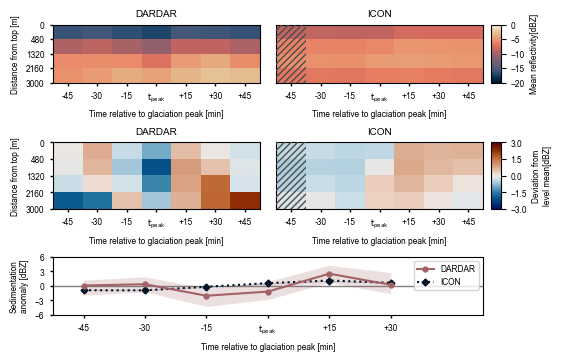

In [36]:
base_dir = Path(
    "/Volumes/University_stuff/Code_Projects/MSGI/plotting/"
    "Publication_figures/data"
)


fig = make_combined_figure(
    model_dir=base_dir / "model",
    observations_dir=base_dir / "observations",
    output_file=base_dir / "model_observations_combined.pdf",
)

plt.show()